# Apple Stock

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Introduction:

We are going to use Apple's stock price.


### Step 1. Import the necessary libraries

In [9]:
import numpy as np
import pandas as pd

### Step 2. Import the dataset from this [address](https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/09_Time_Series/Apple_Stock/appl_1980_2014.csv)

In [10]:
df=pd.read_csv('/content/drive/MyDrive/TEST Fin 2/AAPL.csv')
print(df)

             Date        Open        High         Low       Close   Adj Close  \
0      1980-12-12    0.128348    0.128906    0.128348    0.128348    0.100323   
1      1980-12-15    0.122210    0.122210    0.121652    0.121652    0.095089   
2      1980-12-16    0.113281    0.113281    0.112723    0.112723    0.088110   
3      1980-12-17    0.115513    0.116071    0.115513    0.115513    0.090291   
4      1980-12-18    0.118862    0.119420    0.118862    0.118862    0.092908   
...           ...         ...         ...         ...         ...         ...   
10404  2022-03-18  160.509995  164.479996  159.759995  163.979996  163.979996   
10405  2022-03-21  163.509995  166.350006  163.009995  165.380005  165.380005   
10406  2022-03-22  165.509995  169.419998  164.910004  168.820007  168.820007   
10407  2022-03-23  167.990005  172.639999  167.649994  170.210007  170.210007   
10408  2022-03-24  171.059998  174.139999  170.210007  174.070007  174.070007   

          Volume  
0      4

### Step 3. Assign it to a variable apple

In [11]:
apple=df
apple.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,1980-12-12,0.128348,0.128906,0.128348,0.128348,0.100323,469033600
1,1980-12-15,0.122210,0.122210,0.121652,0.121652,0.095089,175884800
2,1980-12-16,0.113281,0.113281,0.112723,0.112723,0.088110,105728000
3,1980-12-17,0.115513,0.116071,0.115513,0.115513,0.090291,86441600
4,1980-12-18,0.118862,0.119420,0.118862,0.118862,0.092908,73449600


### Step 4.  Check out the type of the columns

In [12]:
apple.dtypes

,0
Date,object
Open,float64
High,float64
Low,float64
Close,float64
Adj Close,float64
Volume,int64


### Step 5. Transform the Date column as a datetime type

In [13]:
apple['Date']=pd.to_datetime(apple['Date'])
apple['Date']

,Date
0,1980-12-12
1,1980-12-15
2,1980-12-16
3,1980-12-17
4,1980-12-18
...,...
10404,2022-03-18
10405,2022-03-21
10406,2022-03-22
10407,2022-03-23


### Step 6.  Set the date as the index

In [14]:
apple=apple.set_index('Date')
apple.head()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
1980-12-12,0.128348,0.128906,0.128348,0.128348,0.100323,469033600
1980-12-15,0.122210,0.122210,0.121652,0.121652,0.095089,175884800
1980-12-16,0.113281,0.113281,0.112723,0.112723,0.088110,105728000
1980-12-17,0.115513,0.116071,0.115513,0.115513,0.090291,86441600
1980-12-18,0.118862,0.119420,0.118862,0.118862,0.092908,73449600


### Step 7.  Is there any duplicate dates?

In [15]:
apple.index.is_unique

True

### Step 8.  Ops...it seems the index is from the most recent date. Make the first entry the oldest date.

In [16]:
apple.sort_index(ascending=True).head()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
1980-12-12,0.128348,0.128906,0.128348,0.128348,0.100323,469033600
1980-12-15,0.122210,0.122210,0.121652,0.121652,0.095089,175884800
1980-12-16,0.113281,0.113281,0.112723,0.112723,0.088110,105728000
1980-12-17,0.115513,0.116071,0.115513,0.115513,0.090291,86441600
1980-12-18,0.118862,0.119420,0.118862,0.118862,0.092908,73449600


### Step 9. Get the last business day of each month

In [17]:
apple_month=apple.resample('BM').mean()
apple_month.head(10)

/tmp/ipykernel_6381/431541888.py:1: FutureWarning: 'BM' is deprecated and will be removed in a future version, please use 'BME' instead.
  apple_month=apple.resample('BM').mean()


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
1980-12-31,0.136075,0.136461,0.135903,0.135903,0.106229,1.034501e+08
1981-01-30,0.141768,0.142086,0.141316,0.141316,0.110459,2.899947e+07
1981-02-27,0.118215,0.118627,0.117892,0.117892,0.092150,1.692733e+07
1981-03-31,0.111328,0.111683,0.110871,0.110871,0.086663,3.185076e+07
1981-04-30,0.121811,0.122183,0.121545,0.121545,0.095006,2.556800e+07
1981-05-29,0.129688,0.130301,0.129436,0.129436,0.101174,2.952096e+07
1981-06-30,0.137505,0.137835,0.137074,0.137074,0.107144,4.320756e+07
1981-07-31,0.109096,0.109527,0.108817,0.108817,0.085057,3.033775e+07
1981-08-31,0.100340,0.100553,0.099835,0.099835,0.078036,2.612480e+07


### Step 10.  What is the difference in days between the first day and the oldest

In [18]:
(apple.index.max()-apple.index.min()).days

15077

### Step 11.  How many months in the data we have?

In [19]:
apple_month=apple.resample('BM').mean()
len(apple_month)

/tmp/ipykernel_6381/2065305205.py:1: FutureWarning: 'BM' is deprecated and will be removed in a future version, please use 'BME' instead.
  apple_month=apple.resample('BM').mean()


496

### Step 12. Plot the 'Adj Close' value. Set the size of the figure to 13.5 x 9 inches

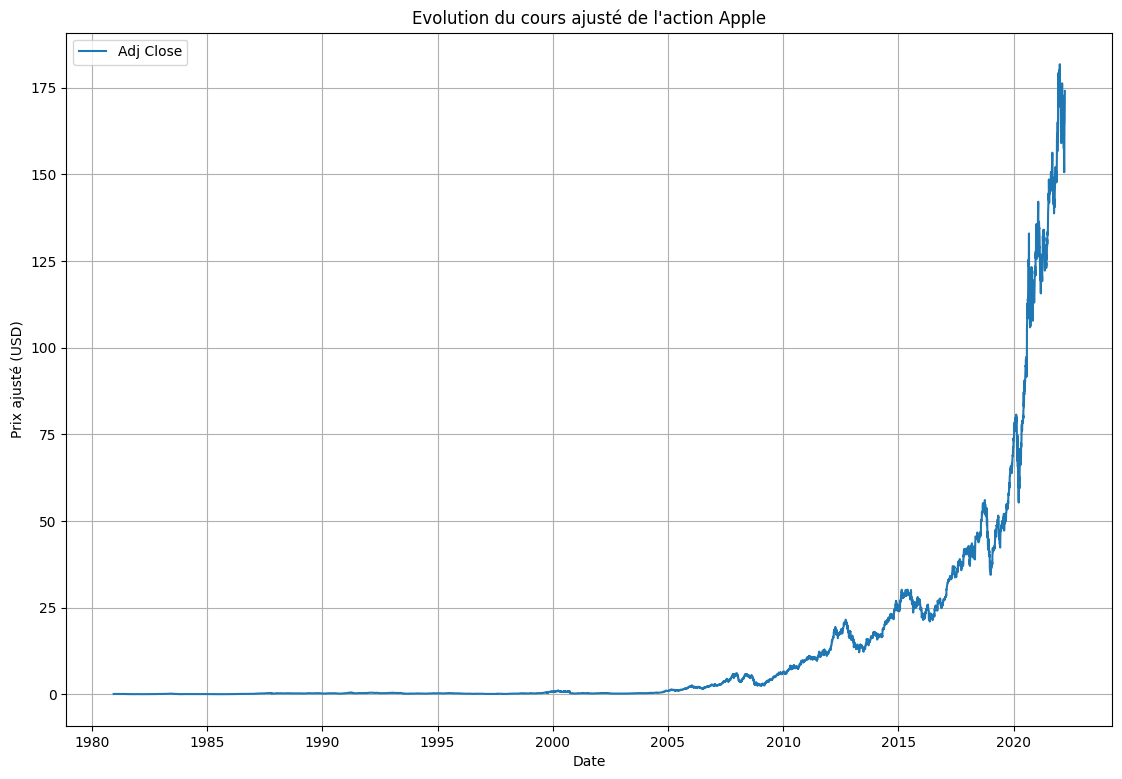

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(13.5, 9))

plt.plot(apple.index, apple['Adj Close'], label='Adj Close')

plt.title("Evolution du cours ajusté de l'action Apple")
plt.xlabel("Date")
plt.ylabel("Prix ajusté (USD)")
plt.legend()
plt.grid(True)

plt.show()

### BONUS: Create your own question and answer it.

In [21]:
# Calcul du prix ajusté au début et à la fin de chaque année
annual_prices = apple['Adj Close'].sort_index().resample('YE').agg(
    ['first', 'last']
)

# Calcul du rendement annuel en pourcentage
annual_prices['Annual Return (%)'] = (
    (annual_prices['last'] - annual_prices['first'])
    / annual_prices['first']
) * 100

# Afficher les rendements annuels
print(annual_prices[['Annual Return (%)']])

# Identifier l'année avec le meilleur rendement
best_year = annual_prices['Annual Return (%)'].idxmax()
best_return = annual_prices.loc[best_year, 'Annual Return (%)']

print("\nAnnée avec le meilleur rendement :", best_year.year)
print("Meilleur rendement annuel : {:.2f}%".format(best_return))

            Annual Return (%)
Date                         
1980-12-31          18.696610
1981-12-31         -35.869854
1982-12-31          35.795699
1983-12-31         -14.473459
1984-12-31          13.659442
1985-12-31         -21.076385
1986-12-31          82.023673
1987-12-31         106.532103
1988-12-31          -9.291019
1989-12-31         -11.835992
1990-12-31          16.870241
1991-12-31          30.810727
1992-12-31           1.296746
1993-12-31         -49.166366
1994-12-31          32.383715
1995-12-31         -15.989603
1996-12-31         -35.019238
1997-12-31         -37.499611
1998-12-31         151.922953
1999-12-31         149.242316
2000-12-31         -73.422669
2001-12-31          47.226619
2002-12-31         -38.497660
2003-12-31          44.391761
2004-12-31         202.631967
2005-12-31         127.176299
2006-12-31          13.498350
2007-12-31         136.372359
2008-12-31         -56.194813
2009-12-31         132.209481
2010-12-31          50.721952
2011-12-31